# Can machine learning forecast Apple's stock price?
**A walk-forward test of random forest, XGBoost and ridge regression on 2014–2023 daily data**

**Summary.** The original version of this project reported an R² of 0.9999 for a random forest "predicting" Apple's closing price. That number comes from predicting *today's* close from *today's* open, high, low and adjusted close, using a random train/test split, so it says nothing about forecasting. Here I redo it as a genuine forecast: predict the **next day's return** using only information available at the close, and test on years the models have never seen, retraining as time moves forward (walk-forward, 2017–2023).

**Result.** No model beats the trivial benchmarks. Out-of-sample R² on next-day returns is ≈ 0 for ridge (+0.1%) and negative for random forest (−0.6%) and XGBoost (−1.3%); directional accuracy is 50–53%, while "always predict up" scores 53.5%. This is what you would expect from a liquid, heavily analysed stock, and the honest conclusion is that these price-history features contain no usable signal.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor

plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.25})
FIG=Path('../figures'); RES=Path('../results'); FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
df=pd.read_csv('../data/aapl_daily.csv',parse_dates=['Date']).set_index('Date')
print(df.shape, df.index.min().date(), 'to', df.index.max().date())
print('missing values:',int(df.isna().sum().sum()),'| duplicate dates:',int(df.index.duplicated().sum()),'| largest gap (days):',int(df.index.to_series().diff().dt.days.max()))
df.describe().T[['mean','min','max']].round(2)

(2475, 6) 2014-01-02 to 2023-10-31
missing values: 0 | duplicate dates: 0 | largest gap (days): 4


,mean,min,max
Open,7.600000e+01,17.68,1.962400e+02
High,7.685000e+01,17.91,1.982300e+02
Low,7.521000e+01,17.63,1.952800e+02
Close,7.606000e+01,17.85,1.964500e+02
Adj Close,7.410000e+01,15.65,1.959300e+02
Volume,1.380565e+08,31458200.00,1.065523e+09


## 1. Data
2,475 trading days of Apple (AAPL) prices, 2 Jan 2014 to 31 Oct 2023 (the earlier write-up said the data ran to 2024; it ends in October 2023). No gaps beyond weekends and holidays, no missing values. Prices are not adjusted for stock splits in `Open/High/Low/Close`, so I use **Adj Close** for returns.

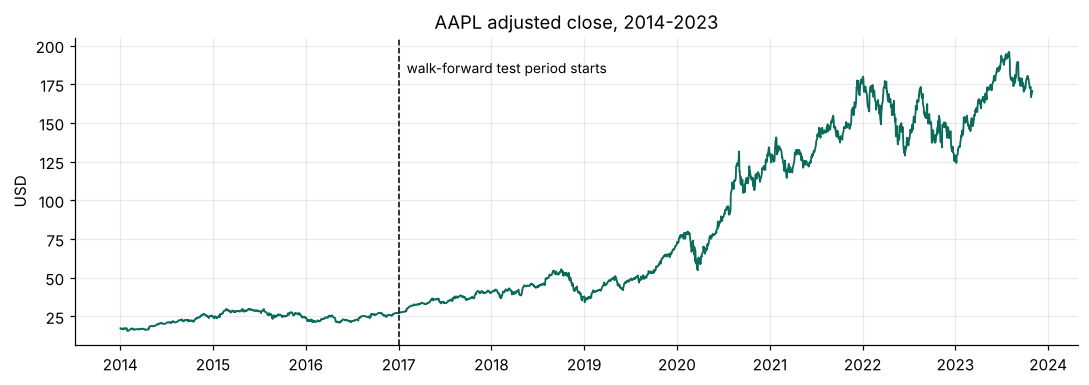

In [2]:
fig,ax=plt.subplots(figsize=(10,3.6))
ax.plot(df['Adj Close'],lw=1.2,color='#0b6b5a'); ax.axvline(pd.Timestamp('2017-01-01'),color='k',ls='--',lw=1)
ax.text(pd.Timestamp('2017-02-01'),df['Adj Close'].max()*.93,'walk-forward test period starts',fontsize=9)
ax.set_title('AAPL adjusted close, 2014-2023'); ax.set_ylabel('USD'); fig.tight_layout(); fig.savefig(FIG/'01_price.png'); plt.show()

## 2. Reproducing the original result, and why it is meaningless
The original notebook predicted `Close` from `Open, High, Low, Adj Close, Volume` of the **same day**, using a random 80/20 split. I reproduce that here.

In [3]:
X=df.drop(columns='Close'); y=df['Close']
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42)
rf=RandomForestRegressor(200,random_state=0,n_jobs=-1).fit(Xtr,ytr)
orig_r2=r2_score(yte,rf.predict(Xte))
# the same "model" using nothing but a constant multiple of Adj Close:
ratio=(df['Close']/df['Adj Close'])
print(f'Original setup (same-day inputs, random split): R2 = {orig_r2:.5f}')
print(f'Corr(Close, Adj Close) = {df.Close.corr(df["Adj Close"]):.5f}; Close/Adj Close ranges {ratio.min():.3f} to {ratio.max():.3f}')

Original setup (same-day inputs, random split): R2 = 0.99995
Corr(Close, Adj Close) = 0.99996; Close/Adj Close ranges 1.001 to 1.141


**Why this is not forecasting.**
1. `Close` and `Adj Close` are the same price on the same day (they differ only by a dividend adjustment), so the model is told the answer.
2. Open, high and low of the same day sit within a few percent of the close.
3. A random split puts neighbouring days in both training and test sets, so the model can interpolate between days it has already seen.

A forecast has to use only what is known *before* the thing being predicted, and be tested on the future.

## 3. A proper forecasting setup
**Target:** next-day log return of Adj Close. Predicting returns, not price levels, removes the trend that makes any price chart look predictable.

**Features (all known at today's close):** returns over 1, 2, 3, 5, 10 and 20 days; 10- and 20-day volatility; price relative to its 10- and 50-day average; change in volume; today's high-low range.

**Evaluation:** expanding-window walk-forward. From 2017 onwards, every 63 trading days (about a quarter) each model is refit on all earlier data and predicts the next 63 days. 1,718 out-of-sample predictions, none of them seen in training.

**Benchmarks:** "zero" (predict no change, the random-walk benchmark) and "drift" (predict the historical average return).

In [4]:
c=df['Adj Close']; r=np.log(c).diff()
F=pd.DataFrame(index=df.index)
for k in (1,2,3,5,10,20): F[f'ret_{k}d']=np.log(c).diff(k)
F['vol_10d']=r.rolling(10).std(); F['vol_20d']=r.rolling(20).std()
F['price_vs_ma10']=c/c.rolling(10).mean()-1; F['price_vs_ma50']=c/c.rolling(50).mean()-1
F['volume_chg']=np.log(df.Volume).diff(); F['hl_range']=(df.High-df.Low)/df.Close
F['y']=r.shift(-1)            # tomorrow's return
D=F.dropna(); X=D.drop(columns='y'); y=D['y']
start=int(np.where(D.index>='2017-01-01')[0][0]); STEP=63
makers={'Ridge':lambda:Ridge(alpha=1.0),
        'Random forest':lambda:RandomForestRegressor(200,min_samples_leaf=20,max_features=.5,n_jobs=-1,random_state=0),
        'XGBoost':lambda:XGBRegressor(n_estimators=150,max_depth=2,learning_rate=.03,subsample=.7,n_jobs=4,random_state=0)}
preds={k:[] for k in makers}; idx=[]
for s in range(start,len(D),STEP):
    e=min(s+STEP,len(D))
    for k,mk in makers.items():
        m=mk().fit(X.iloc[:s-1],y.iloc[:s-1])   # y at s-1 uses the price on day s, so stop one row early
        preds[k]+=list(m.predict(X.iloc[s:e]))
    idx+=list(D.index[s:e])
P=pd.DataFrame(preds,index=idx); yt=y.loc[idx]
P['Zero (random walk)']=0.0
P['Drift (past mean)']=[y.iloc[:i-1].mean() for i in range(start,start+len(idx))]
print(len(yt),'out-of-sample days from',yt.index[0].date(),'to',yt.index[-1].date())

1718 out-of-sample days from 2017-01-03 to 2023-10-30


In [5]:
up=(yt>0).mean(); rows=[]
for k in P:
    e=yt-P[k]; sq=(e**2).sum()
    hit=(np.sign(P[k])==np.sign(yt)).mean() if k!='Zero (random walk)' else np.nan
    rows.append({'model':k,'RMSE':np.sqrt((e**2).mean()),'OOS R2 vs zero':1-sq/(yt**2).sum(),'directional accuracy':hit})
T=pd.DataFrame(rows).set_index('model'); T.loc['Always predict up','directional accuracy']=up
T.round(4).to_csv(RES/'walk_forward_results.csv'); T.round(4)

,RMSE,OOS R2 vs zero,directional accuracy
model,,,
Ridge,0.0191,0.0007,0.5250
Random forest,0.0192,-0.0061,0.5023
XGBoost,0.0193,-0.0130,0.5180
Zero (random walk),0.0191,0.0000,NaN
Drift (past mean),0.0191,0.0025,0.5349
Always predict up,NaN,NaN,0.5349


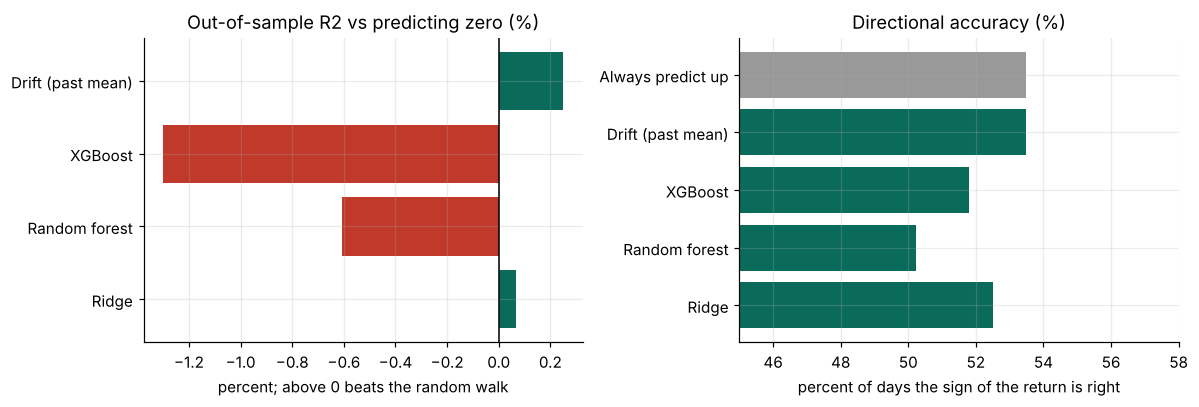

In [6]:
fig,axs=plt.subplots(1,2,figsize=(11,3.8))
m=T.drop(index=['Zero (random walk)','Always predict up'])
axs[0].barh(m.index,m['OOS R2 vs zero']*100,color=['#c0392b' if v<0 else '#0b6b5a' for v in m['OOS R2 vs zero']])
axs[0].axvline(0,color='k',lw=1); axs[0].set_title('Out-of-sample R2 vs predicting zero (%)'); axs[0].set_xlabel('percent; above 0 beats the random walk')
d=T['directional accuracy'].dropna()
axs[1].barh(d.index,d*100,color=['#999999' if i=='Always predict up' else '#0b6b5a' for i in d.index]); axs[1].set_xlim(45,58)
axs[1].set_title('Directional accuracy (%)'); axs[1].set_xlabel('percent of days the sign of the return is right')
fig.tight_layout(); fig.savefig(FIG/'02_walk_forward.png'); plt.show()

### Are any of these differences real?
Paired comparison of squared errors against the zero forecast (Diebold-Mariano style), and a binomial test of each model's hit rate against the 53.5% you get by always saying "up".

In [7]:
out=[]
for k in ['Ridge','Random forest','XGBoost','Drift (past mean)']:
    dsq=(yt-0)**2-(yt-P[k])**2           # positive = model better than zero
    t,p=stats.ttest_1samp(dsq,0)
    hits=int((np.sign(P[k])==np.sign(yt)).sum()); bp=stats.binomtest(hits,len(yt),up,alternative='greater').pvalue
    out.append({'model':k,'mean error reduction vs zero (t-test p)':round(p,3),'beats always-up on direction (p)':round(bp,3)})
S=pd.DataFrame(out).set_index('model'); S.to_csv(RES/'significance_tests.csv'); S

,mean error reduction vs zero (t-test p),beats always-up on direction (p)
model,,
Ridge,0.864,0.801
Random forest,0.487,0.997
XGBoost,0.379,0.923
Drift (past mean),0.322,0.510


No p-value is anywhere near significance, and the signs of the squared-error differences are mixed. These models cannot be distinguished from the benchmark.

## 4. Why forecasting the *price level* with trees looks worse still
Many stock-prediction tutorials predict the price itself. Random forests and XGBoost cannot predict values outside the range they saw in training, so when a stock trends to new highs the forecast flattens out below the true price. Same walk-forward, same features plus the current price level, target = tomorrow's price:

MAE, random forest on price level: 3.91   MAE, "tomorrow = today": 1.32  (USD)


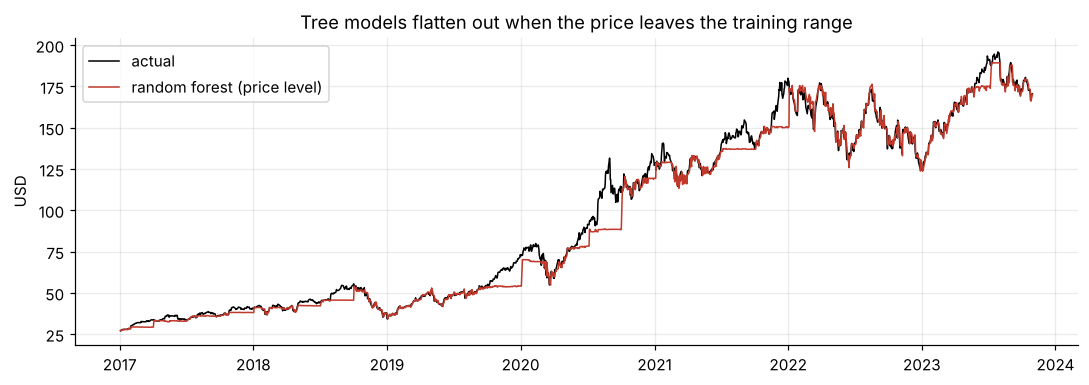

In [8]:
lv=D[[]].copy(); lv['price']=c.loc[D.index]; XL=X.copy(); XL['price']=lv['price']; yL=c.shift(-1).loc[D.index]
pl=[]; ix=[]
for s in range(start,len(D),STEP):
    e=min(s+STEP,len(D))
    m=RandomForestRegressor(200,min_samples_leaf=5,n_jobs=-1,random_state=0).fit(XL.iloc[:s-1],yL.iloc[:s-1])
    pl+=list(m.predict(XL.iloc[s:e])); ix+=list(D.index[s:e])
PL=pd.Series(pl,index=ix); yl=yL.loc[ix]; naive=c.loc[ix]
print(f'MAE, random forest on price level: {mean_absolute_error(yl,PL):.2f}   MAE, "tomorrow = today": {mean_absolute_error(yl,naive):.2f}  (USD)')
fig,ax=plt.subplots(figsize=(10,3.6))
ax.plot(yl,color='k',lw=1,label='actual'); ax.plot(PL,color='#c0392b',lw=1,label='random forest (price level)'); ax.legend(); ax.set_title('Tree models flatten out when the price leaves the training range'); ax.set_ylabel('USD')
fig.tight_layout(); fig.savefig(FIG/'03_level_forecast.png'); plt.show()
pd.DataFrame({'MAE (USD)':{'Random forest on price level':mean_absolute_error(yl,PL),'Tomorrow = today':mean_absolute_error(yl,naive)}}).round(2).to_csv(RES/'price_level_mae.csv')

## 5. Conclusions
- The headline R² of 0.9999 in the original project was an artefact: the target was almost contained in the inputs and the test set was randomly drawn from the same period.
- Under an honest walk-forward test, ridge, random forest and XGBoost add nothing over predicting no change or the historical drift, either in error or in direction.
- Tree models fail on price levels because they cannot extrapolate.
- This is a negative result, but the right one: for a large, liquid stock, public price and volume history alone should not be expected to forecast the next day.

**Limitations.** One stock, one decade (including the 2020 shock and 2022 sell-off). Only price-derived features; news, fundamentals or options data were not tested. No transaction costs or trading strategy is evaluated, and nothing here is investment advice.